# Baseline


Dataset: p4581
Model:   mlp
Train:   1330
Val:     200
Test:    400


Epoch 1/100 [Training]: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 41/41 [00:00<00:00, 154.61it/s, loss=0.12]


Epoch 1 -> Val RMSE: 0.36440
New best model saved: 0.36440


Epoch 2/100 [Training]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 41/41 [00:00<00:00, 145.83it/s, loss=0.0387]


Epoch 2 -> Val RMSE: 0.17617
New best model saved: 0.17617


Epoch 3/100 [Training]: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 41/41 [00:00<00:00, 143.97it/s, loss=0.00579]


... (193 outputs left out)

Epoch 100/100 [Training]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 41/41 [00:00<00:00, 144.90it/s, loss=0.000382]


Epoch 100 -> Val RMSE: 0.03322


Testing: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 400/400 [00:00<00:00, 2038.74it/s]



Dataset: p4581
Model:   mlp
Normal Test RMSE: 0.0358
Normal Test R2:   0.9683
Swap Test RMSE:   0.0516
Swap Test R2:     0.9342


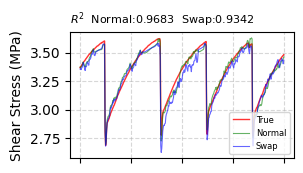

In [12]:
import torch
from torch import nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error
from matplotlib.ticker import FormatStrFormatter, MaxNLocator
import random
import argparse
import os
from math import sqrt
import copy

# ============================================================
# Interface: choose model and dataset here
# ============================================================
MODEL_TYPE = 'mlp'          # 'mlp' / 'lstm' / 'cnn'
DATASET_NAME = 'p4581'      # 'p5198' / 'p4581' / 'p4679'

# ============================================================
# Basic settings
# ============================================================
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

parser = argparse.ArgumentParser(description='Baseline')
parser.add_argument('--lr', default=0.001, type=float)
args = parser.parse_args(args=[])

steps = 70
epochs = 100
batch_size = 32

DATA_PATHS = {
    'p5198': './p5198.csv',
    'p4581': './p4581.csv',
    'p4679': './p4679.csv'
}

data_path = DATA_PATHS[DATASET_NAME]

def set_seed(seed):
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed(42)

# ============================================================
# Data preprocessing
# ============================================================
data = pd.read_csv(data_path)

data_x = data[['var1', 'var2']]
data_y = data[['Shr_stress']]

train_end = int(len(data_y) * 0.7)
val_start = int(len(data_y) * 0.7)
val_end = int(len(data_y) * 0.8)

x_train_raw = data_x[:train_end]
x_val_raw = data_x[val_start-steps:val_end]
x_test_raw = data_x[val_end-steps:]

y_train_raw = data_y[:train_end]
y_val_raw = data_y[val_start-steps:val_end]
y_test_raw = data_y[val_end-steps:]

scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

x_train = scaler_x.fit_transform(x_train_raw.values)
y_train = scaler_y.fit_transform(y_train_raw.values)

x_val = scaler_x.transform(x_val_raw.values)
x_test = scaler_x.transform(x_test_raw.values)

y_val = scaler_y.transform(y_val_raw.values)
y_test = scaler_y.transform(y_test_raw.values)

def create_sliding_windows(x_data, y_data, window_steps):
    X, Y = [], []
    for i in range(window_steps, len(x_data)):
        X.append(x_data[i-window_steps:i])
        Y.append(y_data[i-1])
    return np.array(X, dtype=np.float32), np.array(Y, dtype=np.float32).reshape(-1, 1)

X_train, Y_train = create_sliding_windows(x_train, y_train, steps)
X_val, Y_val = create_sliding_windows(x_val, y_val, steps)
X_test, Y_test = create_sliding_windows(x_test, y_test, steps)

class GetLoader(Dataset):
    def __init__(self, data_root, data_label):
        self.data = data_root
        self.label = data_label

    def __getitem__(self, index):
        return self.data[index], self.label[index]

    def __len__(self):
        return len(self.data)

train_loader = DataLoader(GetLoader(X_train, Y_train), batch_size=batch_size, shuffle=True, drop_last=True)
val_loader = DataLoader(GetLoader(X_val, Y_val), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(GetLoader(X_test, Y_test), batch_size=1, shuffle=False)

print(f'\nDataset: {DATASET_NAME}')
print(f'Model:   {MODEL_TYPE}')
print(f'Train:   {len(X_train)}')
print(f'Val:     {len(X_val)}')
print(f'Test:    {len(X_test)}')

# ============================================================
# MLP
# ============================================================
class MLPModel(nn.Module):
    def __init__(self, steps, var_num=2):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(steps * var_num, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.net(x)

# ============================================================
# LSTM
# ============================================================
class LSTMModel(nn.Module):
    def __init__(self, var_num=2, hidden_size=64, num_layers=2):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=var_num,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        x = out[:, -1, :]
        return self.fc(x)

# ============================================================
# CNN
# ============================================================
class CNNModel(nn.Module):
    def __init__(self, steps, var_num=2):
        super().__init__()

        self.conv1 = nn.Conv1d(var_num, 128, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(128, 84, kernel_size=3, padding=1)
        self.conv3 = nn.Conv1d(84, 64, kernel_size=3, padding=1)

        self.fc = nn.Sequential(
            nn.Linear(64 * steps, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x = x.transpose(1, 2)

        x = torch.relu(self.conv1(x))
        x = torch.relu(self.conv2(x))
        x = torch.relu(self.conv3(x))

        x = x.view(x.size(0), -1)

        return self.fc(x)

# ============================================================
# Select model
# ============================================================
if MODEL_TYPE == 'mlp':
    model = MLPModel(steps).cuda()
elif MODEL_TYPE == 'lstm':
    model = LSTMModel().cuda()
elif MODEL_TYPE == 'cnn':
    model = CNNModel(steps).cuda()
else:
    raise ValueError("MODEL_TYPE must be 'mlp', 'lstm', or 'cnn'")

# ============================================================
# Training
# ============================================================
loss_fn = nn.MSELoss()
optim = torch.optim.Adam(model.parameters(), lr=args.lr)

best_val_rmse = float('inf')
best_model_state = None

for i in range(epochs):

    model.train()
    pbar = tqdm(train_loader, desc=f"Epoch {i+1}/{epochs} [Training]")

    for x, labels in pbar:
        x, labels = x.cuda(), labels.cuda()

        output = model(x)
        loss = loss_fn(output, labels)

        optim.zero_grad()
        loss.backward()
        optim.step()

        pbar.set_postfix({'loss': loss.item()})

    # Validation
    model.eval()
    val_preds, val_trues = [], []

    with torch.no_grad():
        for x_val_batch, y_val_true in val_loader:
            output_val = model(x_val_batch.cuda())
            val_preds.append(output_val.cpu().numpy())
            val_trues.append(y_val_true.numpy())

    val_preds = np.concatenate(val_preds)
    val_trues = np.concatenate(val_trues)

    current_val_rmse = sqrt(mean_squared_error(val_trues, val_preds))

    print(f"Epoch {i+1} -> Val RMSE: {current_val_rmse:.5f}")

    if current_val_rmse < best_val_rmse:
        best_val_rmse = current_val_rmse
        best_model_state = copy.deepcopy(model.state_dict())
        print(f"New best model saved: {best_val_rmse:.5f}")

# Load best model
model.load_state_dict(best_model_state)

# ============================================================
# Normal Test and Swap Test
# ============================================================
model.eval()

normal_preds = []
swap_preds = []

with torch.no_grad():

    for x, _ in tqdm(test_loader, desc="Testing"):

        x = x.cuda()

        # Normal: var1 -> Channel 1, var2 -> Channel 2
        output_normal = model(x)
        normal_preds.append(output_normal.item())

        # Swap: var2 -> Channel 1, var1 -> Channel 2
        x_swap = torch.flip(x, dims=[2])
        output_swap = model(x_swap)
        swap_preds.append(output_swap.item())

normal_preds = np.array(normal_preds)
swap_preds = np.array(swap_preds)

# Metrics in normalized space
normal_rmse = sqrt(mean_squared_error(Y_test, normal_preds))
normal_r2 = r2_score(Y_test, normal_preds)

swap_rmse = sqrt(mean_squared_error(Y_test, swap_preds))
swap_r2 = r2_score(Y_test, swap_preds)

print('\n' + '=' * 50)
print(f'Dataset: {DATASET_NAME}')
print(f'Model:   {MODEL_TYPE}')
print('=' * 50)
print(f'Normal Test RMSE: {normal_rmse:.4f}')
print(f'Normal Test R2:   {normal_r2:.4f}')
print(f'Swap Test RMSE:   {swap_rmse:.4f}')
print(f'Swap Test R2:     {swap_r2:.4f}')

# ============================================================
# Convert predictions back to MPa
# ============================================================
y_true = scaler_y.inverse_transform(Y_test).flatten()
y_pred = scaler_y.inverse_transform(normal_preds.reshape(-1, 1)).flatten()
y_pred_swap = scaler_y.inverse_transform(swap_preds.reshape(-1, 1)).flatten()

# ============================================================
# Plot
# ============================================================
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.size'] = 10
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['axes.edgecolor'] = 'black'

fig, ax = plt.subplots(figsize=(2.8, 2.1))

ax.plot(x_plot, y_true, color='red', alpha=0.8, label='True', linewidth=1.0)
ax.plot(x_plot, y_pred, color='green', alpha=0.6, label='Normal', linewidth=0.8)
ax.plot(x_plot, y_pred_swap, color='blue', alpha=0.6, label='Swap', linewidth=0.8)

ax.legend(fontsize=6, frameon=True, loc='lower right', framealpha=0.8)

ax.set_ylabel('Shear Stress (MPa)')
ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
ax.tick_params(axis='x', labelbottom=False)
ax.grid(True, linestyle='--', alpha=0.5)

text_str = f"$R^2$  Normal:{normal_r2:.4f}  Swap:{swap_r2:.4f}"

ax.text(0.0, 1.03, text_str, transform=ax.transAxes, fontsize=8, va='bottom', ha='left',
        fontfamily='Arial', bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
        alpha=0.0, edgecolor='black', linewidth=1))

plt.subplots_adjust(left=0.15, right=0.95, top=0.80, bottom=0.20)

output_name = f'{DATASET_NAME}_{MODEL_TYPE}_baseline.pdf'
# plt.savefig(output_name, bbox_inches='tight', transparent=True)

plt.show()

# Adaptive


Dataset: p5198
Model:   mlp
Train:   1330
Val:     200
Test:    400


Epoch 1/100 [Training]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 41/41 [00:00<00:00, 91.54it/s, loss=0.00988]


Epoch 1 -> Val RMSE: 0.17350
New best model saved: 0.17350


Epoch 2/100 [Training]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 41/41 [00:00<00:00, 89.20it/s, loss=0.00154]


Epoch 2 -> Val RMSE: 0.13946
New best model saved: 0.13946


Epoch 3/100 [Training]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 41/41 [00:00<00:00, 88.98it/s, loss=0.00169]


... (193 outputs left out)

Epoch 100/100 [Training]: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 41/41 [00:00<00:00, 89.22it/s, loss=0.000169]


Epoch 100 -> Val RMSE: 0.03920


Testing: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 400/400 [00:00<00:00, 939.90it/s]



Dataset: p5198
Model:   mlp
Normal Test RMSE: 0.0259
Normal Test R2:   0.9936
Swap Test RMSE:   0.0259
Swap Test R2:     0.9936


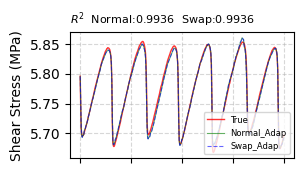

In [14]:
import torch
from torch import nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error
from matplotlib.ticker import FormatStrFormatter, MaxNLocator
import random
import argparse
import os
from math import sqrt
import copy

# ============================================================
# Interface: choose model and dataset here
# ============================================================
MODEL_TYPE = 'mlp'          # 'mlp' / 'lstm' / 'cnn'
DATASET_NAME = 'p5198'      # 'p5198' / 'p4581' / 'p4679'

# ============================================================
# Basic settings
# ============================================================
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

parser = argparse.ArgumentParser(description='DFL')
parser.add_argument('--lr', default=0.001, type=float)
args = parser.parse_args(args=[])

steps = 70
epochs = 100
batch_size = 32

DATA_PATHS = {
    'p5198': './p5198.csv',
    'p4581': './p4581.csv',
    'p4679': './p4679.csv'
}

data_path = DATA_PATHS[DATASET_NAME]

def set_seed(seed):
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed(42)

# ============================================================
# Data preprocessing
# ============================================================
data = pd.read_csv(data_path)

data_x = data[['var1', 'var2']]
data_y = data[['Shr_stress']]

train_end = int(len(data_y) * 0.7)
val_start = int(len(data_y) * 0.7)
val_end = int(len(data_y) * 0.8)

x_train_raw = data_x[:train_end]
x_val_raw = data_x[val_start-steps:val_end]
x_test_raw = data_x[val_end-steps:]

y_train_raw = data_y[:train_end]
y_val_raw = data_y[val_start-steps:val_end]
y_test_raw = data_y[val_end-steps:]

scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

x_train = scaler_x.fit_transform(x_train_raw.values)
y_train = scaler_y.fit_transform(y_train_raw.values)

x_val = scaler_x.transform(x_val_raw.values)
x_test = scaler_x.transform(x_test_raw.values)

y_val = scaler_y.transform(y_val_raw.values)
y_test = scaler_y.transform(y_test_raw.values)

def create_sliding_windows(x_data, y_data, window_steps):
    X, Y = [], []
    for i in range(window_steps, len(x_data)):
        X.append(x_data[i-window_steps:i])
        Y.append(y_data[i-1])
    return np.array(X, dtype=np.float32), np.array(Y, dtype=np.float32).reshape(-1, 1)

X_train, Y_train = create_sliding_windows(x_train, y_train, steps)
X_val, Y_val = create_sliding_windows(x_val, y_val, steps)
X_test, Y_test = create_sliding_windows(x_test, y_test, steps)

class GetLoader(Dataset):
    def __init__(self, data_root, data_label):
        self.data = data_root
        self.label = data_label

    def __getitem__(self, index):
        return self.data[index], self.label[index]

    def __len__(self):
        return len(self.data)

train_loader = DataLoader(GetLoader(X_train, Y_train), batch_size=batch_size, shuffle=True, drop_last=True)
val_loader = DataLoader(GetLoader(X_val, Y_val), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(GetLoader(X_test, Y_test), batch_size=1, shuffle=False)

print(f'\nDataset: {DATASET_NAME}')
print(f'Model:   {MODEL_TYPE}')
print(f'Train:   {len(X_train)}')
print(f'Val:     {len(X_val)}')
print(f'Test:    {len(X_test)}')

# ============================================================
# MLP
# ============================================================
class SharedMLPEncoder(nn.Module):
    def __init__(self, input_steps, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_steps, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim // 2)
        )

    def forward(self, x):
        return self.net(x)

class MLPModel(nn.Module):
    def __init__(self, steps):
        super().__init__()
        self.shared_encoder = SharedMLPEncoder(steps)
        self.attn_net = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
        self.head = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x1, x2 = x[:, :, 0], x[:, :, 1]

        f1 = self.shared_encoder(x1)
        f2 = self.shared_encoder(x2)

        s1 = self.attn_net(f1)
        s2 = self.attn_net(f2)

        weights = F.softmax(torch.cat([s1, s2], dim=1), dim=1)

        f_fused = weights[:, 0:1] * f1 + weights[:, 1:2] * f2

        return self.head(f_fused), weights

# ============================================================
# LSTM
# ============================================================
class SharedLSTM(nn.Module):
    def __init__(self, hidden_size=64, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        return lstm_out[:, -1, :]

class LSTMModel(nn.Module):
    def __init__(self, hidden_size=64):
        super().__init__()

        self.shared_lstm = SharedLSTM(hidden_size=hidden_size)

        self.attention_net = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x1 = x[:, :, 0].unsqueeze(-1)
        x2 = x[:, :, 1].unsqueeze(-1)

        f1 = self.shared_lstm(x1)
        f2 = self.shared_lstm(x2)

        s1 = self.attention_net(f1)
        s2 = self.attention_net(f2)

        weights = F.softmax(torch.cat([s1, s2], dim=1), dim=1)

        f_fused = weights[:, 0:1] * f1 + weights[:, 1:2] * f2

        return self.fc(f_fused), weights

# ============================================================
# CNN
# ============================================================
class SharedCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv1d(1, 128, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(128, 84, kernel_size=3, padding=1)
        self.conv3 = nn.Conv1d(84, 64, kernel_size=3, padding=1)

    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = torch.relu(self.conv2(x))
        x = torch.relu(self.conv3(x))
        return x

class CNNModel(nn.Module):
    def __init__(self, steps):
        super().__init__()

        self.shared_cnn = SharedCNN()

        self.attention_net = nn.Sequential(
            nn.Linear(64 * steps, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

        self.fc = nn.Sequential(
            nn.Linear(64 * steps, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x1 = x[:, :, 0].unsqueeze(1)
        x2 = x[:, :, 1].unsqueeze(1)

        f1 = self.shared_cnn(x1)
        f2 = self.shared_cnn(x2)

        f1_flat = f1.view(f1.size(0), -1)
        f2_flat = f2.view(f2.size(0), -1)

        s1 = self.attention_net(f1_flat)
        s2 = self.attention_net(f2_flat)

        weights = F.softmax(torch.cat([s1, s2], dim=1), dim=1)

        f_fused = weights[:, 0:1] * f1_flat + weights[:, 1:2] * f2_flat

        return self.fc(f_fused), weights

# ============================================================
# Select model
# ============================================================
if MODEL_TYPE == 'mlp':
    model = MLPModel(steps).cuda()
elif MODEL_TYPE == 'lstm':
    model = LSTMModel().cuda()
elif MODEL_TYPE == 'cnn':
    model = CNNModel(steps).cuda()
else:
    raise ValueError("MODEL_TYPE must be 'mlp', 'lstm', or 'cnn'")

# ============================================================
# Training
# ============================================================
loss_fn = nn.MSELoss()
optim = torch.optim.Adam(model.parameters(), lr=args.lr)

best_val_rmse = float('inf')
best_model_state = None

for i in range(epochs):

    model.train()
    pbar = tqdm(train_loader, desc=f"Epoch {i+1}/{epochs} [Training]")

    for x, labels in pbar:
        x, labels = x.cuda(), labels.cuda()

        output, _ = model(x)
        loss = loss_fn(output, labels)

        optim.zero_grad()
        loss.backward()
        optim.step()

        pbar.set_postfix({'loss': loss.item()})

    # Validation
    model.eval()
    val_preds, val_trues = [], []

    with torch.no_grad():
        for x_val_batch, y_val_true in val_loader:
            output_val, _ = model(x_val_batch.cuda())
            val_preds.append(output_val.cpu().numpy())
            val_trues.append(y_val_true.numpy())

    val_preds = np.concatenate(val_preds)
    val_trues = np.concatenate(val_trues)

    current_val_rmse = sqrt(mean_squared_error(val_trues, val_preds))

    print(f"Epoch {i+1} -> Val RMSE: {current_val_rmse:.5f}")

    if current_val_rmse < best_val_rmse:
        best_val_rmse = current_val_rmse
        best_model_state = copy.deepcopy(model.state_dict())
        print(f"New best model saved: {best_val_rmse:.5f}")

# Load best model
model.load_state_dict(best_model_state)

# ============================================================
# Normal Test and Swap Test
# ============================================================
model.eval()

normal_preds = []
swap_preds = []

with torch.no_grad():

    for x, _ in tqdm(test_loader, desc="Testing"):

        x = x.cuda()

        # Normal: var1 -> Channel 1, var2 -> Channel 2
        output_normal, _ = model(x)
        normal_preds.append(output_normal.item())

        # Swap: var2 -> Channel 1, var1 -> Channel 2
        x_swap = torch.flip(x, dims=[2])
        output_swap, _ = model(x_swap)
        swap_preds.append(output_swap.item())

normal_preds = np.array(normal_preds)
swap_preds = np.array(swap_preds)

# Metrics in normalized space
normal_rmse = sqrt(mean_squared_error(Y_test, normal_preds))
normal_r2 = r2_score(Y_test, normal_preds)

swap_rmse = sqrt(mean_squared_error(Y_test, swap_preds))
swap_r2 = r2_score(Y_test, swap_preds)

print('\n' + '=' * 50)
print(f'Dataset: {DATASET_NAME}')
print(f'Model:   {MODEL_TYPE}')
print('=' * 50)
print(f'Normal Test RMSE: {normal_rmse:.4f}')
print(f'Normal Test R2:   {normal_r2:.4f}')
print(f'Swap Test RMSE:   {swap_rmse:.4f}')
print(f'Swap Test R2:     {swap_r2:.4f}')

# ============================================================
# Convert predictions back to MPa
# ============================================================
y_true = scaler_y.inverse_transform(Y_test).flatten()
y_pred = scaler_y.inverse_transform(normal_preds.reshape(-1, 1)).flatten()
y_pred_swap = scaler_y.inverse_transform(swap_preds.reshape(-1, 1)).flatten()

# ============================================================
# Plot
# ============================================================
x_plot = np.arange(len(y_true))

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.size'] = 10
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['axes.edgecolor'] = 'black'

fig, ax = plt.subplots(figsize=(2.8, 2.1))

ax.plot(x_plot, y_true, color='red', alpha=0.8, label='True', linewidth=1.0)
ax.plot(x_plot, y_pred, color='green', alpha=0.6, label='Normal_Adap', linewidth=0.8, linestyle='-')
ax.plot(x_plot, y_pred_swap, color='blue', alpha=0.6, label='Swap_Adap', linewidth=0.8, linestyle='--')

ax.legend(fontsize=6, frameon=True, loc='lower right', framealpha=0.8)

ax.set_ylabel('Shear Stress (MPa)')
ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
ax.tick_params(axis='x', labelbottom=False)
ax.grid(True, linestyle='--', alpha=0.5)

text_str = f"$R^2$  Normal:{normal_r2:.4f}  Swap:{swap_r2:.4f}"

ax.text(0.0, 1.03, text_str, transform=ax.transAxes, fontsize=8, va='bottom', ha='left',
        fontfamily='Arial', bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
        alpha=0.0, edgecolor='black', linewidth=1))

plt.subplots_adjust(left=0.15, right=0.95, top=0.80, bottom=0.20)

output_name = f'{DATASET_NAME}_{MODEL_TYPE}_adaptive.pdf'
# plt.savefig(output_name, bbox_inches='tight', transparent=True)

plt.show()